In [9]:
import sys

print(sys.executable)

/home/robin/projets/projet_MLops/Supply-Chain-MLOps/.venv/bin/python


# Data loading and overview

In [10]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as ss

In [11]:
df = pd.read_csv('../data/raw/avis_40k.csv', sep=';', header=0)
print("data loading and overview")

display(df.head())
display(df.info())
display(df.describe())

data loading and overview


,auteur,note,titre,commentaire,date_experience,date_avis,url,texteServiceReply,dateServiceReply,dataServiceReply
0,FREDERIC (Bordeaux),4,Produit conforme,Produit conforme. La description du contenue e...,"February 13, 2026",A day ago,https://www.trustpilot.com/review/oscaro.com,NaN,NaN,NaN
1,Patrice,5,Comportement professionnel,NaN,"February 11, 2026",3 days ago,https://www.trustpilot.com/review/oscaro.com,NaN,NaN,NaN
2,Client daniel,4,R.A.S,..............R.A.S.........,"January 31, 2026",3 days ago,https://www.trustpilot.com/review/oscaro.com,NaN,NaN,NaN
3,Derek Mcmillan,5,Excellent.,NaN,"February 4, 2026","Feb 4, 2026",https://www.trustpilot.com/review/oscaro.com,Reply from Oscaro,"Feb 5, 2026","Bonjour Derek, Je vous remercie pour votre ret..."
4,GM,4,Tres bien mais attention bien scotcher…,Tres bien mais attention bien scotcher les col...,"January 30, 2026","Feb 1, 2026",https://www.trustpilot.com/review/oscaro.com,Reply from Oscaro,"Feb 3, 2026","Bonjour Grégoire , Je vous remercie pour votre..."


<class 'pandas.DataFrame'>
RangeIndex: 40000 entries, 0 to 39999
Data columns (total 10 columns):
 #   Column             Non-Null Count  Dtype
---  ------             --------------  -----
 0   auteur             40000 non-null  str  
 1   note               40000 non-null  int64
 2   titre              40000 non-null  str  
 3   commentaire        36225 non-null  str  
 4   date_experience    40000 non-null  str  
 5   date_avis          40000 non-null  str  
 6   url                40000 non-null  str  
 7   texteServiceReply  33146 non-null  str  
 8   dateServiceReply   33146 non-null  str  
 9   dataServiceReply   33146 non-null  str  
dtypes: int64(1), str(9)
memory usage: 22.2 MB


None

,note
count,40000.00000
mean,4.02915
std,1.40819
min,1.00000
25%,3.00000
50%,5.00000
75%,5.00000
max,5.00000


# Problem Definition

* As a starting point, it is always a good idea to clearly define **what the objective is**. In this project, the aim is to automatically categorize customer reviews. We are therefore dealing with a **semantic clustering** problem. Consequently, there is no target variable in the same sense as in supervised learning. However, particular attention should be paid to the metrics used to evaluate the quality of the resulting clusters.

* The feature used for semantic embedding and clustering is the `commentaire` column, which contains all customer reviews. These reviews (approximately 40,000) were scraped from the Trustpilot website and concern the company Oscaro. The other features will only be used for exploratory data analysis.

# Missing Value Handling and Feature Removal

Missing value handling
3775
Na % among reviews: 9.4375
            auteur  note                           titre commentaire  \
1          Patrice     5      Comportement professionnel         NaN   
3   Derek Mcmillan     5                      Excellent.         NaN   
7     Masnou Bruno     5      Super.....................         NaN   
16          Anouar     5                  Good good good         NaN   
19           Aslan     1  Nulle je déconseille set sites         NaN   

      date_experience     date_avis  \
1   February 11, 2026    3 days ago   
3    February 4, 2026   Feb 4, 2026   
7    January 15, 2026  Jan 16, 2026   
16  December 15, 2025  Dec 17, 2025   
19  November 27, 2025  Nov 27, 2025   

                                             url  texteServiceReply  \
1   https://www.trustpilot.com/review/oscaro.com                NaN   
3   https://www.trustpilot.com/review/oscaro.com  Reply from Oscaro   
7   https://www.trustpilot.com/review/oscaro.com  Reply from Osc

Text(0.5, 1.0, 'NaN proportion among clients reviews')

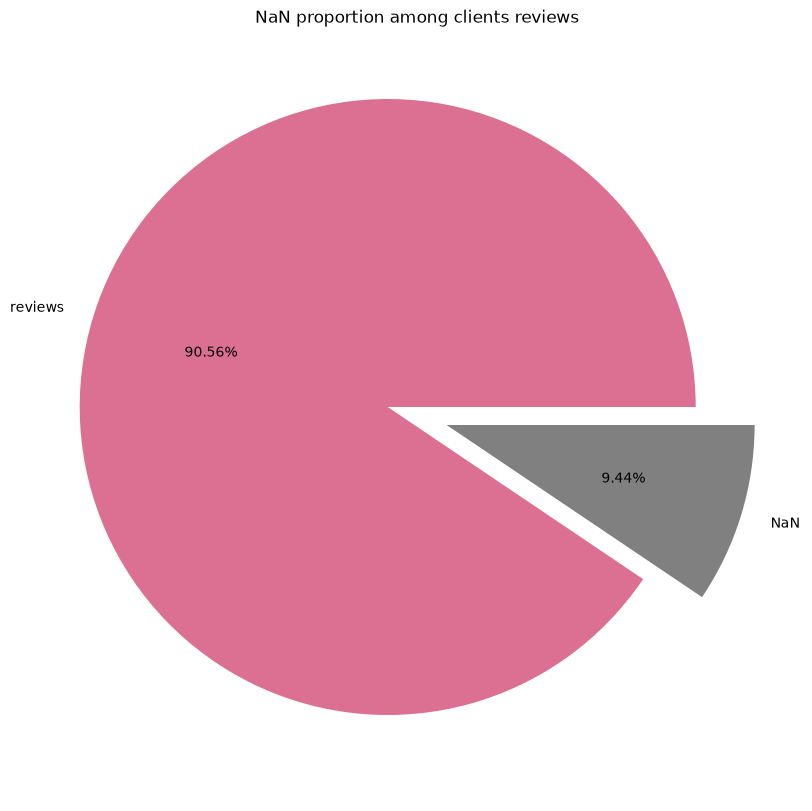

In [12]:
print('Missing value handling')

print(df['commentaire'].isna().sum())
print('Na % among reviews:', df['commentaire'].isna().sum()/len(df['commentaire'])*100)
print(df[df['commentaire'].isna()].head())


plt.figure(figsize=(10,10))
plt.pie(df["commentaire"].isna().value_counts(normalize=True),
            labels=['reviews', 'NaN'],
            explode=[0.1, 0.1],
            autopct="%0.2f%%",
            colors=["palevioletred", "grey"])
plt.title('NaN proportion among clients reviews')

In [13]:
df['commentaire'] = df['commentaire'].fillna(df['titre']) # Replace NaN values with the corresponding review titles
df[['commentaire', 'auteur', 'date_avis']] = df[['commentaire', 'auteur', 'date_avis']].drop_duplicates() # duplicates deletion
df = df.drop('date_avis', axis=1) 
df = df.drop('texteServiceReply', axis=1)
df = df.drop('url', axis = 1)
df = df.drop('dateServiceReply', axis = 1)

display(df.info())
display(df.head())

<class 'pandas.DataFrame'>
RangeIndex: 40000 entries, 0 to 39999
Data columns (total 6 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   auteur            39948 non-null  str  
 1   note              40000 non-null  int64
 2   titre             40000 non-null  str  
 3   commentaire       39948 non-null  str  
 4   date_experience   40000 non-null  str  
 5   dataServiceReply  33146 non-null  str  
dtypes: int64(1), str(5)
memory usage: 17.2 MB


None

,auteur,note,titre,commentaire,date_experience,dataServiceReply
0,FREDERIC (Bordeaux),4,Produit conforme,Produit conforme. La description du contenue e...,"February 13, 2026",NaN
1,Patrice,5,Comportement professionnel,Comportement professionnel,"February 11, 2026",NaN
2,Client daniel,4,R.A.S,..............R.A.S.........,"January 31, 2026",NaN
3,Derek Mcmillan,5,Excellent.,Excellent.,"February 4, 2026","Bonjour Derek, Je vous remercie pour votre ret..."
4,GM,4,Tres bien mais attention bien scotcher…,Tres bien mais attention bien scotcher les col...,"January 30, 2026","Bonjour Grégoire , Je vous remercie pour votre..."


# Language handling

In [14]:
from langdetect import detect
from langdetect import DetectorFactory
DetectorFactory.seed = 34

def to_detect(text_i): # language detection
    try :
        return detect(text_i)
    except:
        return ('NA')

df["lang"] = df["commentaire"].apply(lambda x: to_detect(x))
print(df['lang'].value_counts())
print(df['lang'].describe(include='O'))

lang
fr    38261
ca      360
es      316
en      289
de      128
it      123
pt      122
ro      105
NA       78
nl       47
vi       25
lv       18
id       16
af       16
hu       13
sk       11
et       10
fi        9
so        7
sv        7
pl        6
tl        6
da        5
lt        4
sq        4
tr        3
no        3
cy        3
bg        1
ru        1
cs        1
sw        1
hr        1
Name: count, dtype: int64
count     40000
unique       33
top          fr
freq      38261
Name: lang, dtype: object


In [15]:
display(df.info())
display(df.head())

<class 'pandas.DataFrame'>
RangeIndex: 40000 entries, 0 to 39999
Data columns (total 7 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   auteur            39948 non-null  str  
 1   note              40000 non-null  int64
 2   titre             40000 non-null  str  
 3   commentaire       39948 non-null  str  
 4   date_experience   40000 non-null  str  
 5   dataServiceReply  33146 non-null  str  
 6   lang              40000 non-null  str  
dtypes: int64(1), str(6)
memory usage: 17.5 MB


None

,auteur,note,titre,commentaire,date_experience,dataServiceReply,lang
0,FREDERIC (Bordeaux),4,Produit conforme,Produit conforme. La description du contenue e...,"February 13, 2026",NaN,fr
1,Patrice,5,Comportement professionnel,Comportement professionnel,"February 11, 2026",NaN,fr
2,Client daniel,4,R.A.S,..............R.A.S.........,"January 31, 2026",NaN,hu
3,Derek Mcmillan,5,Excellent.,Excellent.,"February 4, 2026","Bonjour Derek, Je vous remercie pour votre ret...",ca
4,GM,4,Tres bien mais attention bien scotcher…,Tres bien mais attention bien scotcher les col...,"January 30, 2026","Bonjour Grégoire , Je vous remercie pour votre...",fr


In [16]:
df = df[df["lang"] == "fr"] # Keep only French-language reviews
df = df.dropna(subset=['commentaire'])
df.head()
df.info()

<class 'pandas.DataFrame'>
Index: 38261 entries, 0 to 39999
Data columns (total 7 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   auteur            38261 non-null  str  
 1   note              38261 non-null  int64
 2   titre             38261 non-null  str  
 3   commentaire       38261 non-null  str  
 4   date_experience   38261 non-null  str  
 5   dataServiceReply  31736 non-null  str  
 6   lang              38261 non-null  str  
dtypes: int64(1), str(6)
memory usage: 17.3 MB


# Temporal data visualization

In [18]:
# chronological sorting of reviews
df["date_to_sort"] = pd.to_datetime(
    df["date_experience"],
    format="%B %d, %Y",
)

df = df.sort_values("date_to_sort").reset_index(drop=True)

# Data Splitting for Different MLOps Stages
# Initial training : 60 %
df_train = df.iloc[:24000].copy()

# Monitoring reference : 10 %
df_reference = df.iloc[24000:28000].copy()

# Simulated production : 20 %
df_production = df.iloc[28000:36000].copy()

# Final evaluation : 10 %
df_test = df.iloc[36000:].copy()


date_experience_month
5     0.130708
11    0.104336
8     0.102925
6     0.100991
10    0.098691
7     0.098037
1     0.086407
12    0.086171
9     0.074018
4     0.065367
2     0.045529
3     0.006822
Name: proportion, dtype: float64

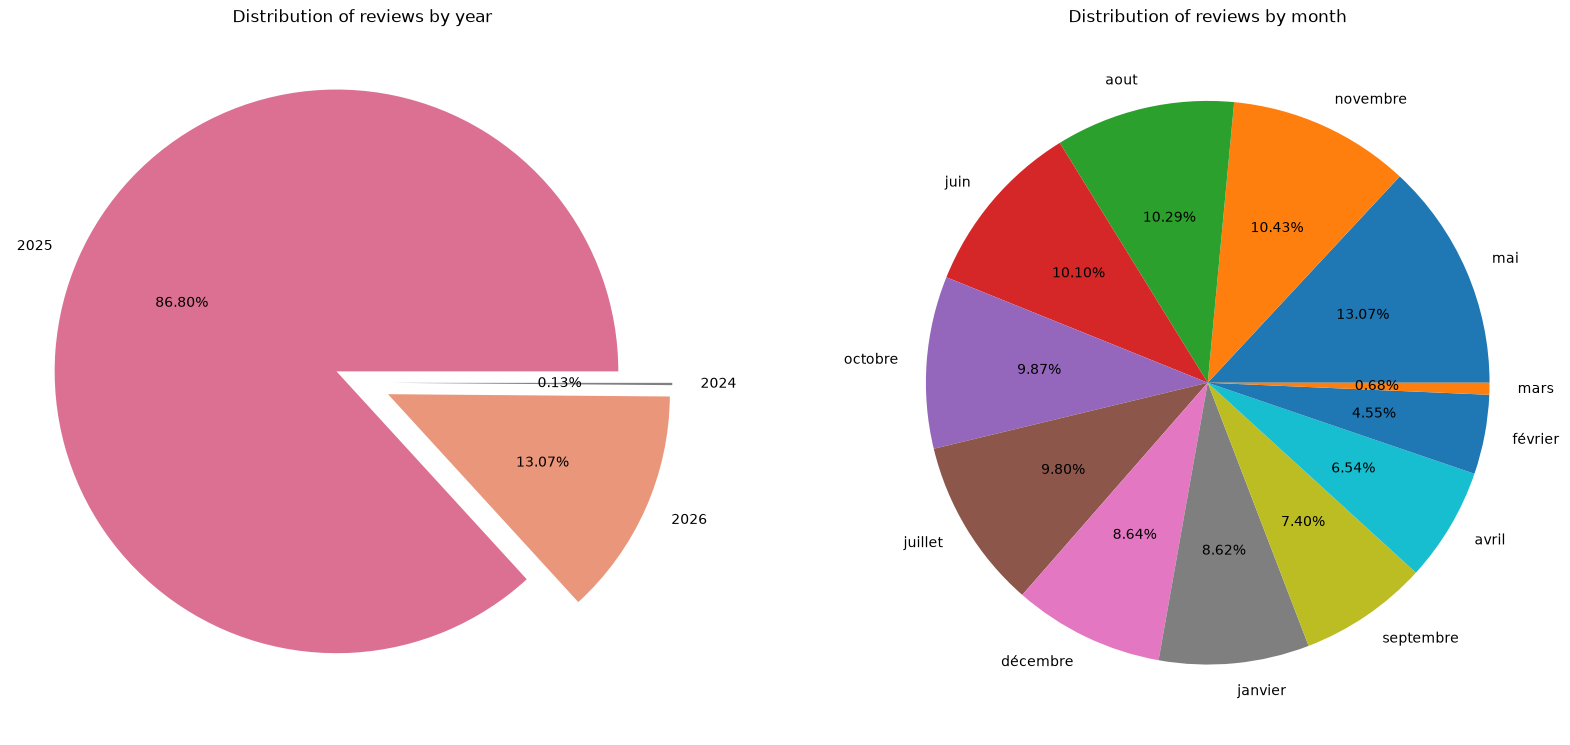

In [19]:
month_to_number = {'January' : 1, 'February' : 2, 'March' : 3, 'April' : 4, 'May' : 5, 'June' : 6, 'July' : 7, 'August' : 8, 'September' : 9, 'October' : 10, 'November' : 11, 'December' : 12}

df['date_experience_year'] = df['date_experience'].str[-4:] 
df['date_experience_month'] = df['date_experience'].replace(month_to_number, regex=True).astype(int)
df['date_experience_year'] = df['date_experience_year'].astype(int)
df = df.drop('date_experience', axis=1)

df['comm_reply'] = np.where(df['dataServiceReply'].isna() == False, df['commentaire'] + df['dataServiceReply'], df['commentaire'])

df['length_comm'] = df['commentaire'].apply(lambda x: len(x))

plt.figure(figsize=(20,10))

plt.subplot(121)

plt.pie(df["date_experience_year"].value_counts(normalize=True),
            labels=['2025', '2026', '2024'],
            explode=[0.1, 0.1, 0.1],
            autopct="%0.2f%%",
            colors=["palevioletred", "darksalmon", "grey"])
plt.title('Distribution of reviews by year')

plt.subplot(122)

plt.pie(df["date_experience_month"].value_counts(normalize=True),
            labels=['mai', 'novembre', 'aout', 'juin', 'octobre', 'juillet', 'décembre', 'janvier', 'septembre', 'avril', 'février', 'mars'],
            #explode=[0.1, 0.1, 0.1],
            autopct="%0.2f%%")
            #colors=["palevioletred", "darksalmon", "grey"])
plt.title('Distribution of reviews by month')


df["date_experience_month"].value_counts(normalize=True)

# Distribution of ratings and review lengths

Text(0.5, 1.0, 'review length median as a function of ratings')

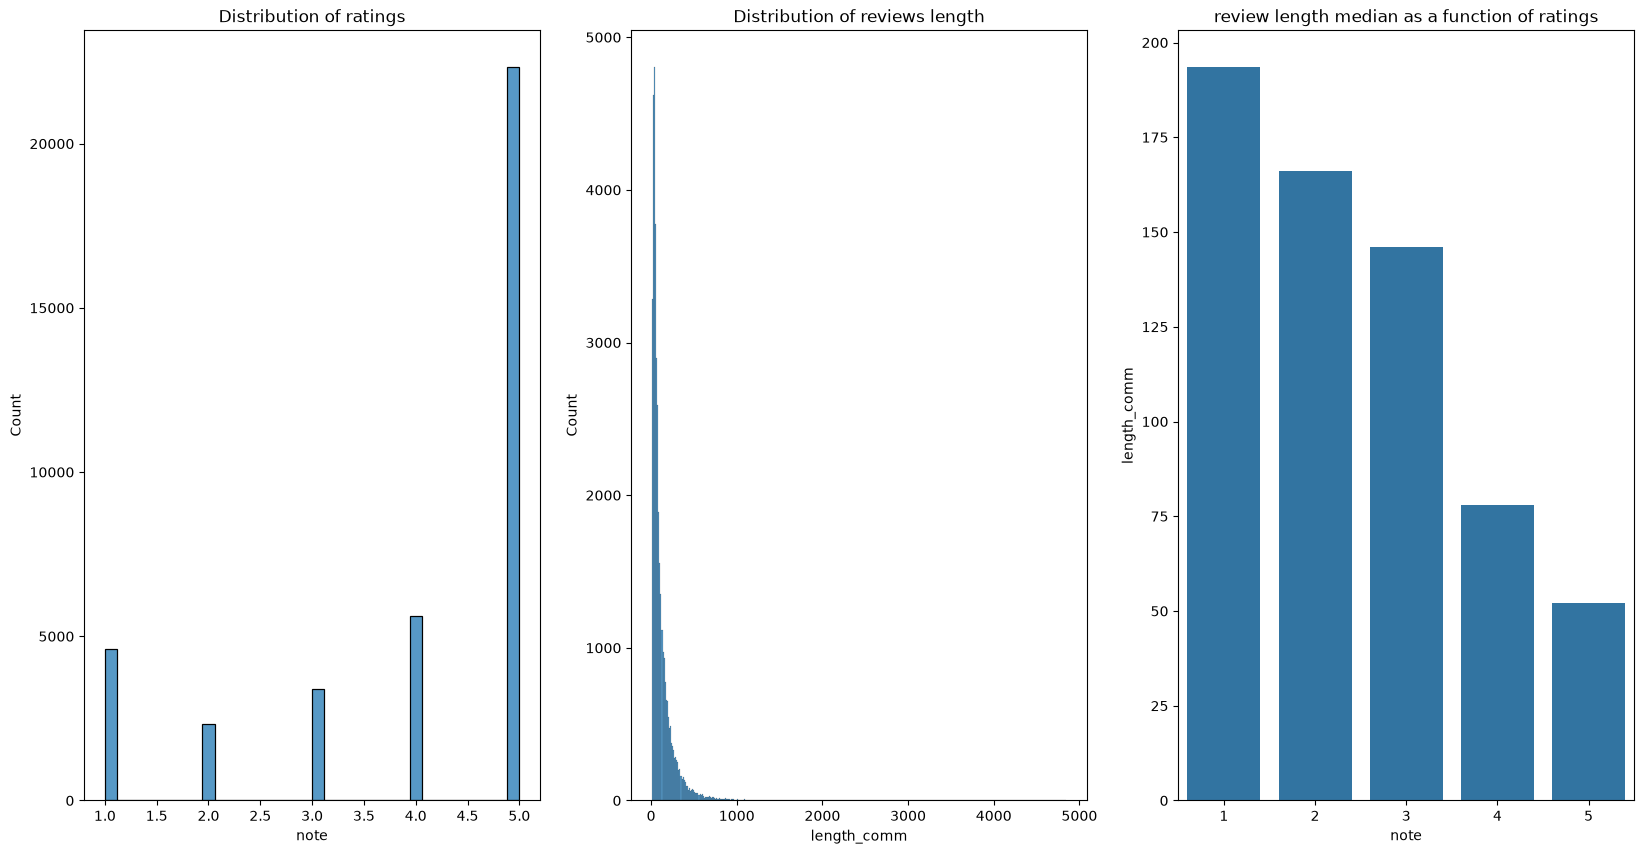

In [21]:
plt.figure(figsize=(20,10))

plt.subplot(131)

sns.histplot(df['note'])
plt.title('Distribution of ratings')

plt.subplot(132)

sns.histplot(df['length_comm'])
plt.title('Distribution of reviews length')

plt.subplot(133)

sns.barplot(data= df[['note','length_comm']].groupby('note').median(), x='note', y='length_comm')
plt.title('review length median as a function of ratings')

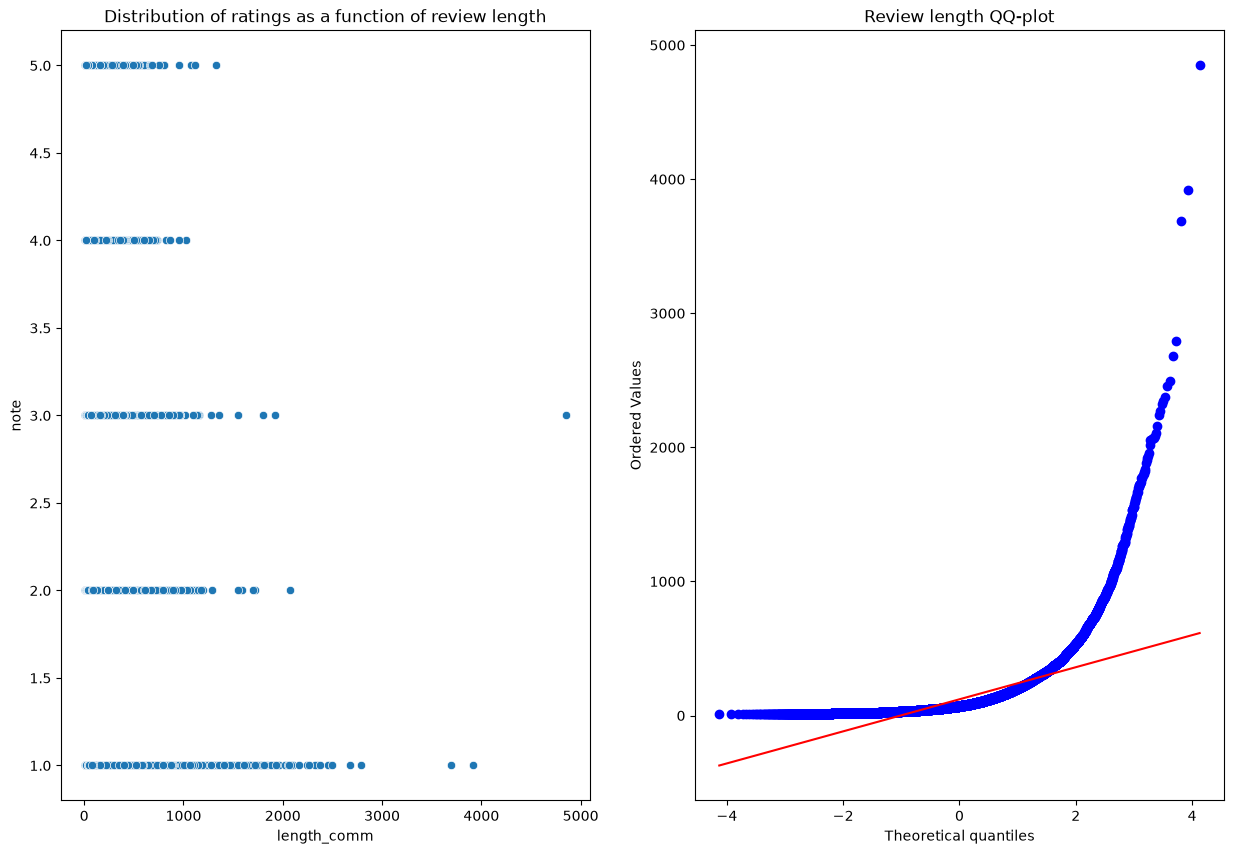

                note  length_comm
note         1.00000     -0.46309
length_comm -0.46309      1.00000
data normality, shapiro's p.value: 4.0613871572304055e-75
pearson correlation coef: -0.46308957127179995
pearson correlation p.value: 0.0
kendall correlation coef: -0.3734948642650401
kendall correlation p.value: 0.0


In [22]:
plt.figure(figsize=(15,10))
plt.subplot(1,2,1)
sns.scatterplot(x=df['length_comm'], y=df['note'])
plt.title('Distribution of ratings as a function of review length')
plt.subplot(122)
ss.probplot(df['length_comm'], plot=plt)
plt.title('Review length QQ-plot')
plt.show()



#plt.subplot(223)
#sns.lmplot(x='length_comm', y='note', data=df, )

print(df[['note', 'length_comm']].corr())

print('data normality, shapiro\'s p.value:', ss.shapiro(df['length_comm'].head(5000))[1])
print('pearson correlation coef:', ss.pearsonr(df['length_comm'], df['note'])[0])
print('pearson correlation p.value:', ss.pearsonr(df['length_comm'], df['note'])[1])
print('kendall correlation coef:', ss.kendalltau(df['length_comm'], df['note'])[0])
print('kendall correlation p.value:', ss.kendalltau(df['length_comm'], df['note'])[1])

# Data export

In [47]:
df_train.to_csv('../data/processed/avis_24k_train.csv') # initial training
df_reference.to_csv('../data/processed/avis_4k_reference.csv') # monitoring reference
df_production.to_csv('../data/processed/avis_8k_production.csv') # simulated production
df_test.to_csv('../data/processed/avis_3k_test.csv') # final test

# Wordcloud

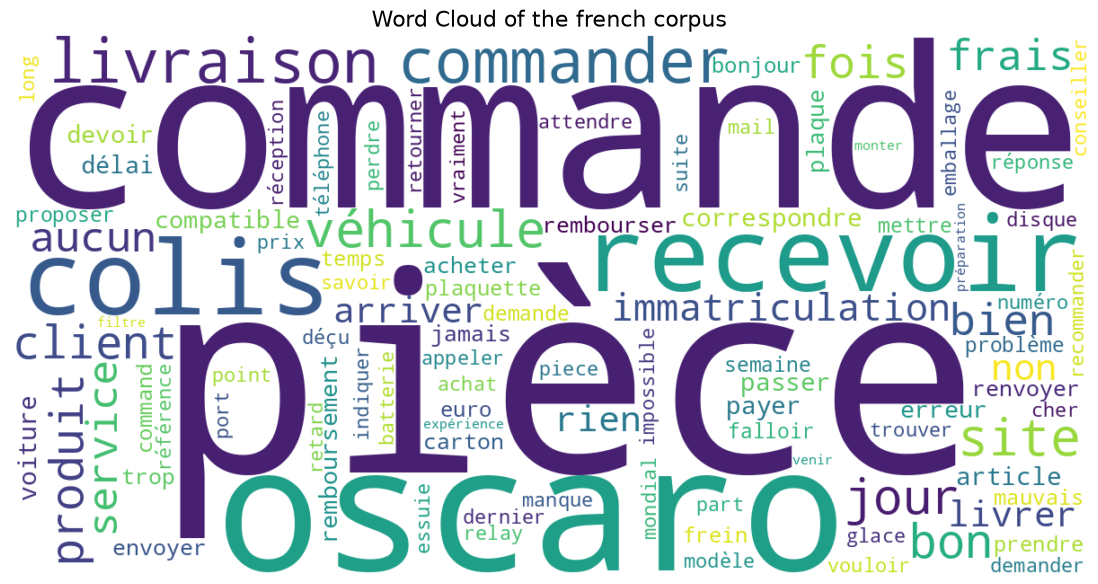

In [23]:
import spacy
from collections import Counter
from wordcloud import WordCloud

# loading french linguistic model
nlp = spacy.load("fr_core_news_sm")

# additional stopwords
custom_stopwords = {
    "être", "avoir", "faire", "dire",
    "aller", "voir", "pouvoir"
}

def preprocess_text(text):
    """
    Text Cleaning, lemmatization and tokenization
    """
    doc = nlp(text.lower())

    tokens = [
        token.lemma_.lower()
        for token in doc
        if not token.is_stop
        and not token.is_punct
        and not token.is_space
        and not token.like_url
        and not token.like_email
        and token.is_alpha
        and len(token.lemma_) > 2
        and token.lemma_.lower() not in custom_stopwords
    ]

    return tokens


texts = df[df['note']==1]['commentaire']
tokens = []
for text in texts:
    tokens.extend(preprocess_text(text))

frequencies = Counter(tokens)

# WordCloud generation
wc = WordCloud(
    width=1200,
    height=600,
    background_color="white",
    max_words=100,
    collocations=False,
    random_state=42
).generate_from_frequencies(frequencies)

# Visualization
plt.figure(figsize=(14, 7))
plt.imshow(wc, interpolation="bilinear")
plt.axis("off")
plt.title("Word Cloud of the french corpus", fontsize=16)
plt.show()